# House-value regression in R

Topic 8 · Dimensionality reduction and feature selection

The goal is to predict `MEDV` from the 13 supplied numerical predictors and measure how much predictive quality is retained when fewer inputs are passed to a Random Forest. The supplied Topic 8 notebooks inform the workflow. This analysis uses regression models, continuous target colours and regression metrics.

Run all cells with an R kernel and keep `house_data.csv` in the notebook working directory. The analysis uses ranger, glmnet, Rtsne and uwot. Package versions are listed in Section 10.

## 1. Load, inspect, and document the data

The local CSV contains one record per observation. `MEDV` is a continuous house-value target. All other columns are treated as numerical inputs. Keep unusual observations, including values at the upper end of the observed target range.

In [1]:
options(width = 95, digits = 5, repr.plot.res = 120)
invisible(loadNamespace("ranger"))
seed <- 42L
target <- "MEDV"
raw <- read.csv("house_data.csv", check.names = FALSE)
stopifnot(target %in% names(raw), all(vapply(raw, is.numeric, logical(1))))

features <- setdiff(names(raw), target)
missing <- colSums(is.na(raw))
duplicates <- sum(duplicated(raw))
constant <- vapply(
  raw[features], function(x) length(unique(x[!is.na(x)])) <= 1L, logical(1)
)
data <- raw[!duplicated(raw), ]
stopifnot(!anyNA(data[[target]]))

cat("Original dimensions:", nrow(raw), "rows x", ncol(raw), "columns\n")
print(round(head(raw, 5), 4), row.names = FALSE)
print(data.frame(
  Column = names(raw), Type = vapply(raw, class, character(1)),
  Missing = missing
), row.names = FALSE)
print(data.frame(
  Check = c("Original rows", "Final rows", "Predictors",
            "Missing predictor values", "Missing target values",
            "Exact duplicate rows removed", "Constant predictors"),
  Count = c(nrow(raw), nrow(data), length(features), sum(missing[features]),
            missing[target], duplicates, sum(constant))
), row.names = FALSE)
cat("Constant predictor names:",
    if (any(constant)) paste(features[constant], collapse = ", ") else "None",
    "\n")

Original dimensions: 506 rows x 14 columns


   CRIM ZN INDUS CHAS    NX    RM  AGE    DIS RAD TAX PTRATIO      B LSTAT MEDV
 0.0063 18  2.31    0 0.538 6.575 65.2 4.0900   1 296    15.3 396.90  4.98 24.0
 0.0273  0  7.07    0 0.469 6.421 78.9 4.9671   2 242    17.8 396.90  9.14 21.6
 0.0273  0  7.07    0 0.469 7.185 61.1 4.9671   2 242    17.8 392.83  4.03 34.7
 0.0324  0  2.18    0 0.458 6.998 45.8 6.0622   3 222    18.7 394.63  2.94 33.4
 0.0690  0  2.18    0 0.458 7.147 54.2 6.0622   3 222    18.7 396.90  5.33 36.2


  Column    Type Missing
    CRIM numeric       0
      ZN numeric       0
   INDUS numeric       0
    CHAS integer       0
      NX numeric       0
      RM numeric       0
     AGE numeric       0
     DIS numeric       0
     RAD integer       0
     TAX numeric       0
 PTRATIO numeric       0
       B numeric       0
   LSTAT numeric       0
    MEDV numeric       0


                        Check Count
                Original rows   506
                   Final rows   506
                   Predictors    13
     Missing predictor values     0
        Missing target values     0
 Exact duplicate rows removed     0
          Constant predictors     0


Constant predictor names: None 


## 2. Fix the split and prevent data leakage

Use one random 80/20 split with seed 42. Estimate medians and scaling parameters on the training predictors and apply those parameters to both partitions. All reduction decisions use the training partition. Test metrics are computed together in Section 7 after all settings are fixed.

In [2]:
set.seed(seed)
train_index <- sample.int(nrow(data), floor(0.8 * nrow(data)))
test_index <- setdiff(seq_len(nrow(data)), train_index)
X_train <- data[train_index, features, drop = FALSE]
X_test <- data[test_index, features, drop = FALSE]
y_train <- data[train_index, target]
y_test <- data[test_index, target]

medians <- vapply(X_train, median, numeric(1), na.rm = TRUE)
fill_missing <- function(x) {
  for (name in names(medians)) {
    x[[name]][is.na(x[[name]])] <- medians[[name]]
  }
  x
}
train_imputed <- fill_missing(X_train)
test_imputed <- fill_missing(X_test)
train_scaled <- scale(train_imputed)
test_scaled <- scale(
  test_imputed, center = attr(train_scaled, "scaled:center"),
  scale = attr(train_scaled, "scaled:scale")
)
stopifnot(!(target %in% colnames(train_scaled)),
          length(intersect(train_index, test_index)) == 0L)
cat("Split seed:", seed, "\n")
cat("Training:", length(y_train), "rows | Test:", length(y_test), "rows\n")

Split seed: 42 


Training: 404 rows | Test: 102 rows


## 3. Establish the Random Forest baseline

Use all 13 prepared predictors. Every forest uses 300 bootstrap trees, seed 42, and considers all available inputs at each split. Use one worker for timing. For regression, ranger defaults to variance splitting, no depth limit, a minimum node size of five for splitting, and a minimum terminal bucket size of one, and out-of-bag error calculation. With replacement, the default sample fraction is 1. Only the forest fit is timed.

           Mean      SD     Min  Median     Max
CRIM      3.878   9.303   0.006   0.269  88.976
ZN       10.632  22.575   0.000   0.000  95.000
INDUS    11.437   6.834   0.740   9.900  27.740
CHAS      0.064   0.246   0.000   0.000   1.000
NX        0.558   0.117   0.385   0.538   0.871
RM        6.268   0.704   3.561   6.194   8.780
AGE      69.226  28.233   2.900  79.050 100.000
DIS       3.753   2.108   1.137   3.096  10.710
RAD       9.728   8.795   1.000   5.000  24.000
TAX     412.067 170.754 188.000 334.000 711.000
PTRATIO  18.547   2.117  12.600  19.100  22.000
B       358.308  88.339   2.600 391.395 396.900
LSTAT    12.684   7.057   1.730  11.430  37.970


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    5.0    16.8    21.1    22.3    25.0    50.0 


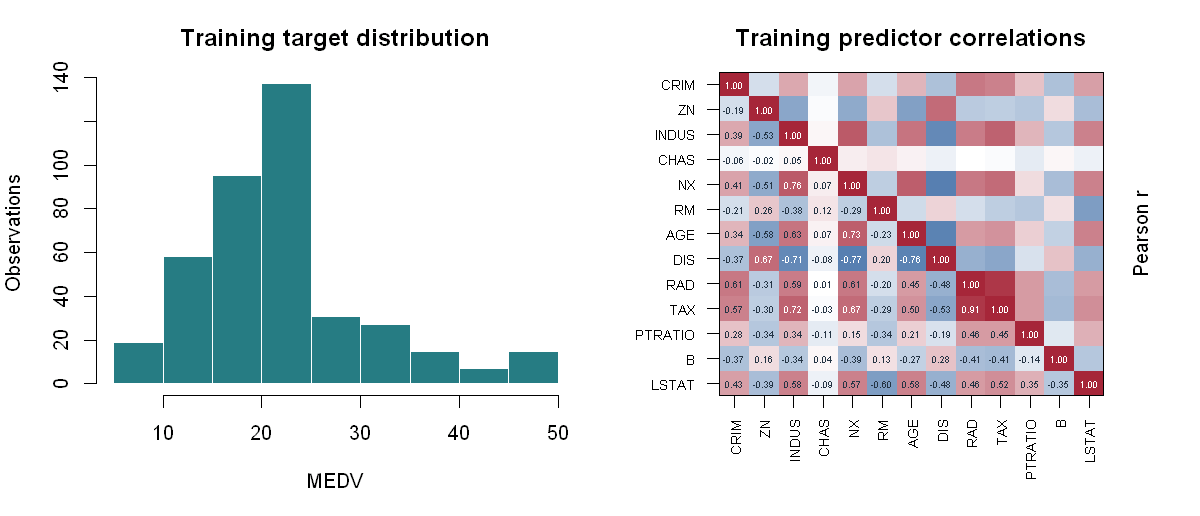

In [3]:
predictor_summary <- t(vapply(
  train_imputed,
  function(x) c(Mean = mean(x), SD = sd(x), Min = min(x),
                Median = median(x), Max = max(x)),
  numeric(5)
))
print(round(predictor_summary, 3))
print(summary(y_train))
corr <- cor(train_imputed)

options(repr.plot.width = 10, repr.plot.height = 4.3)
old_par <- par(mfrow = c(1, 2), mar = c(5, 4, 3, 1))
hist(y_train, breaks = 16, col = "#267c83", border = "white",
     main = "Training target distribution", xlab = "MEDV", ylab = "Observations")
par(mar = c(5, 5, 3, 4))
n <- length(features)
cor_colours <- colorRampPalette(c("#285c9c", "white", "#a62639"))(101)
image(seq_len(n), seq_len(n), corr[, n:1], col = cor_colours,
      zlim = c(-1, 1), axes = FALSE, xlab = "", ylab = "",
      main = "Training predictor correlations")
axis(1, seq_len(n), features, las = 2, cex.axis = 0.72)
axis(2, seq_len(n), rev(features), las = 2, cex.axis = 0.72)
for (i in seq_len(n)) {
  for (j in i:n) {
    value <- corr[i, j]
    text(i, n + 1 - j, sprintf("%.2f", value), cex = 0.43,
         col = if (abs(value) > 0.65) "white" else "#243444")
  }
}
box()
mtext("Pearson r", side = 4, line = 1)
invisible(par(old_par))

In [4]:
fit_forest <- function(train_matrix) {
  train_frame <- as.data.frame(train_matrix)
  start <- proc.time()[["elapsed"]]
  forest <- ranger::ranger(
    x = train_frame, y = y_train, num.trees = 300L,
    mtry = ncol(train_frame), replace = TRUE, seed = seed, num.threads = 1L
  )
  list(model = forest, time = proc.time()[["elapsed"]] - start)
}
baseline_fit <- fit_forest(train_scaled)
cat(sprintf("Baseline Random Forest fit: %.3f s\n", baseline_fit$time))

Baseline Random Forest fit: 0.310 s


## 4. Apply PCA before Random Forest

Fit PCA by SVD with training centring and scaling inside `prcomp`, as in the sample R notebook. A 90% training variance target keeps most observed predictor variation while allowing compression. The first component count to reach the threshold determines the forest inputs. Pass the imputed test matrix to `predict`, which applies the training scaling and loadings once.

 Component Explained_pct Cumulative_pct
         1         46.13          46.13
         2         11.23          57.36
         3          9.53          66.89
         4          7.02          73.90
         5          6.54          80.45
         6          5.08          85.53
         7          4.29          89.82
         8          3.02          92.84
         9          2.15          94.99
        10          1.84          96.83
        11          1.41          98.24
        12          1.29          99.53
        13          0.47         100.00


Threshold: 90% | Retained: 8 | Retained variance: 92.84%


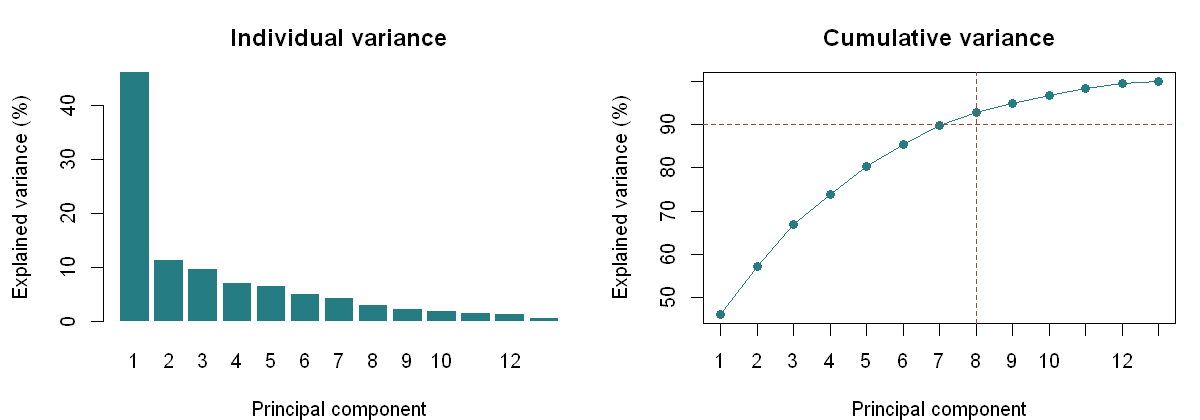

In [5]:
pca <- prcomp(train_imputed, center = TRUE, scale. = TRUE)
train_scores <- pca$x
test_scores <- predict(pca, newdata = test_imputed)
stopifnot(isTRUE(all.equal(test_scores, test_scaled %*% pca$rotation)))
variance <- pca$sdev^2 / sum(pca$sdev^2)
cumulative <- cumsum(variance)
components <- seq_along(variance)
threshold <- 0.90
k <- which(cumulative >= threshold)[1]
print(data.frame(
  Component = components, Explained_pct = round(100 * variance, 2),
  Cumulative_pct = round(100 * cumulative, 2)
), row.names = FALSE)
cat(sprintf("Threshold: %.0f%% | Retained: %d | Retained variance: %.2f%%\n",
            100 * threshold, k, 100 * cumulative[k]))

options(repr.plot.width = 10, repr.plot.height = 3.5)
old_par <- par(mfrow = c(1, 2), mar = c(4, 4.3, 3, 1))
barplot(100 * variance, names.arg = components, col = "#267c83", border = NA,
        main = "Individual variance", xlab = "Principal component",
        ylab = "Explained variance (%)")
plot(components, 100 * cumulative, type = "o", pch = 19, col = "#267c83",
     xaxt = "n", main = "Cumulative variance", xlab = "Principal component",
     ylab = "Explained variance (%)")
axis(1, at = components)
abline(h = 100 * threshold, v = k, lty = 2, col = "#9b4b31")
invisible(par(old_par))

pca_fit <- fit_forest(train_scores[, seq_len(k), drop = FALSE])

## 5. Apply Lasso selection before Random Forest

Inspect manually listed penalty strengths and their training coefficients. Use the weakest listed strength that removes at least three inputs while retaining at least one. This gives a concrete compression target without consulting test scores. A predictor is active when its absolute coefficient exceeds 1e-6. The intercept is excluded.

            0.03    0.10    0.20    0.35    0.55    0.80    1.20
CRIM     -1.0058 -0.7881 -0.4858 -0.3474 -0.2038 -0.0733  0.0000
ZN        0.6724  0.3666  0.0311  0.0000  0.0000  0.0000  0.0000
INDUS    -0.0450 -0.1521 -0.0854  0.0000  0.0000  0.0000  0.0000
CHAS      0.4730  0.4651  0.4241  0.3129  0.1837  0.0000  0.0000
NX       -1.8632 -1.5117 -0.9629 -0.3417  0.0000  0.0000  0.0000
RM        2.5288  2.6264  2.7481  2.7585  2.7144  2.5866  2.3506
AGE      -0.0286  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
DIS      -2.7640 -2.2160 -1.4649 -0.7271 -0.0945  0.0000  0.0000
RAD       2.2113  1.1373  0.1295  0.0000  0.0000  0.0000  0.0000
TAX      -1.5101 -0.5848  0.0000  0.0000  0.0000  0.0000  0.0000
PTRATIO  -2.0455 -1.9546 -1.7912 -1.6377 -1.4998 -1.3713 -1.1257
B         0.7069  0.6621  0.5942  0.5431  0.4246  0.2534  0.0000
LSTAT    -3.7657 -3.7763 -3.7800 -3.7674 -3.6473 -3.6050 -3.5514
Retained 13.0000 12.0000 11.0000  8.0000  7.0000  5.0000  3.0000


Chosen Lasso lambda: 0.35 | Retained: 8 


Selected predictors: CRIM, CHAS, NX, RM, DIS, PTRATIO, B, LSTAT 


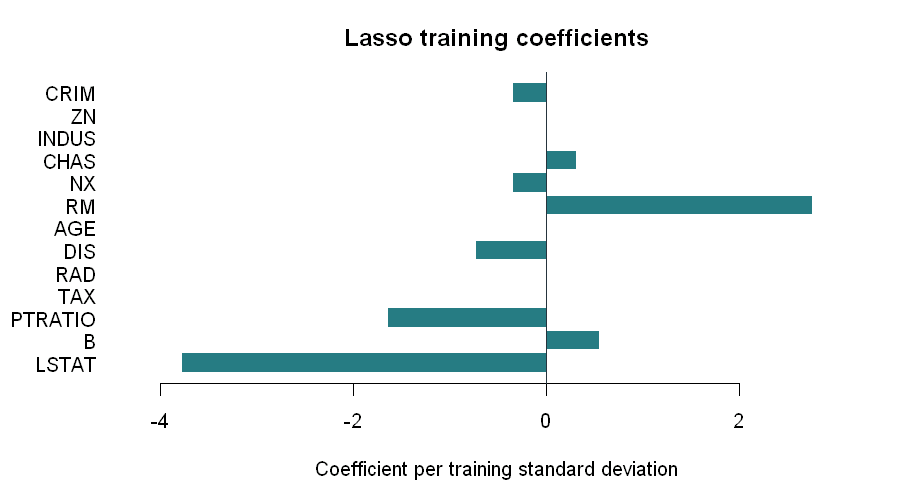

In [6]:
penalties <- c(0.03, 0.10, 0.20, 0.35, 0.55, 0.80, 1.20)
cutoff <- 1e-6

inspect_penalties <- function(mixing) {
  fit <- glmnet::glmnet(
    train_scaled, y_train, family = "gaussian", alpha = mixing,
    lambda = sort(penalties, decreasing = TRUE), standardize = FALSE,
    control = list(thresh = 1e-12, maxit = 100000L)
  )
  stopifnot(fit$jerr == 0L)
  trial <- as.matrix(coef(fit, s = penalties))[-1, , drop = FALSE]
  colnames(trial) <- format(penalties)
  active <- abs(trial) > cutoff
  counts <- colSums(active)
  print(round(rbind(trial, Retained = counts), 4))
  chosen <- which(counts >= 1L & counts <= length(features) - 3L)[1]
  stopifnot(!is.na(chosen))
  list(penalty = penalties[chosen], coefficients = trial[, chosen],
       features = rownames(trial)[active[, chosen]])
}

plot_coefficients <- function(selection, name) {
  options(repr.plot.width = 7.5, repr.plot.height = 4)
  old_par <- par(mar = c(4, 5, 3, 1))
  coefficients <- rev(selection$coefficients)
  colours <- ifelse(names(coefficients) %in% selection$features,
                    "#267c83", "#bec7cc")
  barplot(coefficients, horiz = TRUE, las = 1, col = colours, border = NA,
          xlim = extendrange(coefficients, f = 0.1),
          main = paste(name, "training coefficients"),
          xlab = "Coefficient per training standard deviation")
  abline(v = 0, col = "#26343d")
  invisible(par(old_par))
}

lasso <- inspect_penalties(mixing = 1)
cat("Chosen Lasso lambda:", lasso$penalty,
    "| Retained:", length(lasso$features), "\n")
cat("Selected predictors:", paste(lasso$features, collapse = ", "), "\n")
plot_coefficients(lasso, "Lasso")
lasso_fit <- fit_forest(train_scaled[, lasso$features, drop = FALSE])

## 6. Apply Elastic Net selection before Random Forest

Fix the L1 mixing ratio at 0.5 to combine sparsity with L2 shrinkage. Inspect the same penalty candidates and apply the same training-only retention rule. This is a separate selector fit using the original standardised predictors.

            0.03    0.10    0.20    0.35    0.55    0.80    1.20
CRIM     -1.0448 -0.9242 -0.7649 -0.5493 -0.4187 -0.3574 -0.2578
ZN        0.7218  0.5559  0.3313  0.0782  0.0000  0.0000  0.0000
INDUS    -0.0398 -0.1161 -0.1962 -0.1772 -0.0228  0.0000  0.0000
CHAS      0.4788  0.4784  0.4751  0.4493  0.3810  0.2953  0.1664
NX       -1.9082 -1.7060 -1.4134 -0.9979 -0.5980 -0.1957  0.0000
RM        2.5176  2.5690  2.6445  2.7306  2.7581  2.7322  2.6473
AGE      -0.0640  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
DIS      -2.8670 -2.5269 -2.1011 -1.5192 -0.9507 -0.4163  0.0000
RAD       2.3829  1.7717  0.9924  0.2116  0.0000  0.0000  0.0000
TAX      -1.6552 -1.1305 -0.4824  0.0000  0.0000  0.0000  0.0000
PTRATIO  -2.0580 -2.0013 -1.9220 -1.7945 -1.6766 -1.5735 -1.4445
B         0.7183  0.6953  0.6652  0.6158  0.5718  0.5299  0.4147
LSTAT    -3.7462 -3.7460 -3.7187 -3.6770 -3.6179 -3.5323 -3.3657
Retained 13.0000 12.0000 12.0000 11.0000  9.0000  8.0000  6.0000


Chosen Elastic Net lambda: 0.55 | L1 ratio: 0.5 | Retained: 9 


Selected predictors: CRIM, INDUS, CHAS, NX, RM, DIS, PTRATIO, B, LSTAT 


Shared: CRIM, CHAS, NX, RM, DIS, PTRATIO, B, LSTAT 


Lasso only: None 


Elastic Net only: INDUS 


      CRIM CHAS   NX    RM   DIS PTRATIO     B LSTAT
INDUS 0.39 0.05 0.76 -0.38 -0.71    0.34 -0.34  0.58


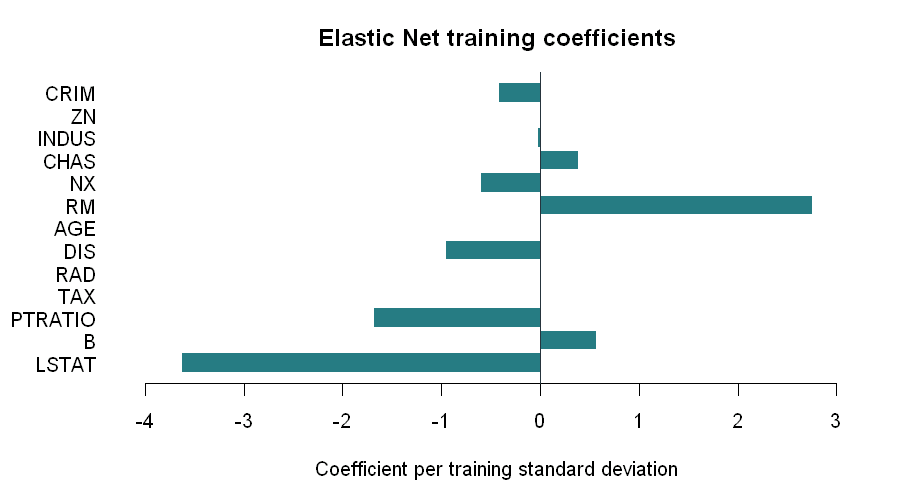

In [7]:
mixing <- 0.5
elastic <- inspect_penalties(mixing)
cat("Chosen Elastic Net lambda:", elastic$penalty, "| L1 ratio:", mixing,
    "| Retained:", length(elastic$features), "\n")
cat("Selected predictors:", paste(elastic$features, collapse = ", "), "\n")
plot_coefficients(elastic, "Elastic Net")
en_fit <- fit_forest(train_scaled[, elastic$features, drop = FALSE])

shared <- intersect(lasso$features, elastic$features)
lasso_only <- setdiff(lasso$features, elastic$features)
en_only <- setdiff(elastic$features, lasso$features)
different <- union(lasso_only, en_only)
describe <- function(x) if (length(x)) paste(x, collapse = ", ") else "None"
cat("Shared:", describe(shared), "\n")
cat("Lasso only:", describe(lasso_only), "\n")
cat("Elastic Net only:", describe(en_only), "\n")
print(round(corr[different, shared, drop = FALSE], 2))

## 7. Compare all four pipelines on the test set

RMSE and MAE are in MEDV units. R² is computed against the mean of the held-out observations. All panels use the same observations and axis limits. The dashed diagonal represents perfect agreement. Times measure a single one-worker fit and can vary across runs.

         Pipeline Inputs   RMSE    MAE      R2 RF fit time (s)
         Baseline     13 2.8494 2.1841 0.92093            0.31
         PCA + RF      8 4.2014 2.5833 0.82809            0.32
       Lasso + RF      8 2.9521 2.2790 0.91513            0.21
 Elastic Net + RF      9 2.9438 2.2768 0.91560            0.24


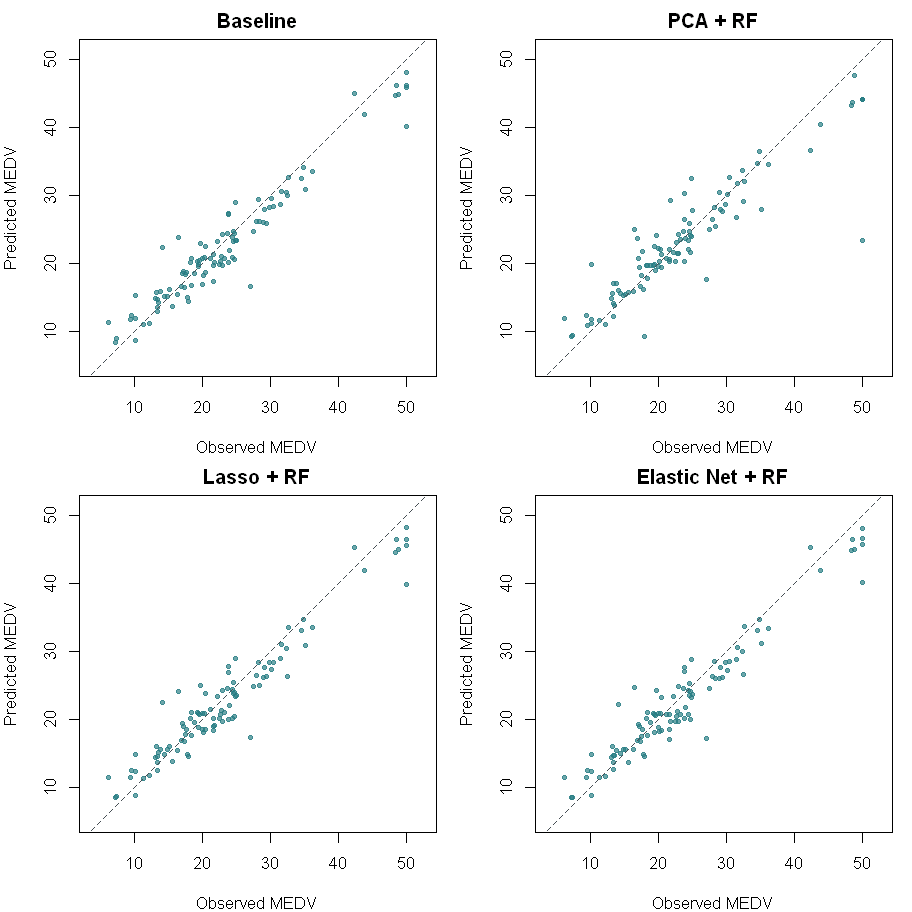

In [8]:
forests <- list("Baseline" = baseline_fit, "PCA + RF" = pca_fit,
                "Lasso + RF" = lasso_fit, "Elastic Net + RF" = en_fit)
test_matrices <- list(
  test_scaled, test_scores[, seq_len(k), drop = FALSE],
  test_scaled[, lasso$features, drop = FALSE],
  test_scaled[, elastic$features, drop = FALSE]
)
predictions <- Map(function(fit, x) {
  predict(fit$model, data = as.data.frame(x), num.threads = 1L)$predictions
}, forests, test_matrices)

results <- data.frame(Pipeline = names(forests), row.names = NULL)
results$Inputs <- vapply(test_matrices, ncol, integer(1))
results$RMSE <- vapply(predictions, function(p) {
  sqrt(mean((y_test - p)^2))
}, numeric(1))
results$MAE <- vapply(predictions, function(p) mean(abs(y_test - p)), numeric(1))
results$R2 <- vapply(predictions, function(p) {
  1 - sum((y_test - p)^2) / sum((y_test - mean(y_test))^2)
}, numeric(1))
results[["RF fit time (s)"]] <- vapply(forests, function(f) f$time, numeric(1))
print(results, row.names = FALSE)

options(repr.plot.width = 7.6, repr.plot.height = 7.6)
limits <- range(c(y_test, unlist(predictions))) + c(-1, 1)
old_par <- par(mfrow = c(2, 2), mar = c(4, 4, 2, 1))
for (name in names(predictions)) {
  plot(y_test, predictions[[name]], main = name, xlim = limits, ylim = limits,
       asp = 1, xlab = "Observed MEDV", ylab = "Predicted MEDV",
       pch = 19, cex = 0.72, col = adjustcolor("#267c83", alpha.f = 0.67))
  abline(0, 1, lty = 2, col = "#454d53")
}
invisible(par(old_par))

## 8. Visualise PCA and t-SNE

Embed the same standardised training rows each time. Use `MEDV` only to colour points after fitting. All embedding plots share the Viridis scale over the training target range. Use Euclidean t-SNE with random initialisation, learning rate 200, early exaggeration 12, Barnes-Hut theta 0.5, and 1,000 iterations. Disable Rtsne's internal PCA and normalisation. Reuse the perplexity-30, seed-42 result in the seed comparison.

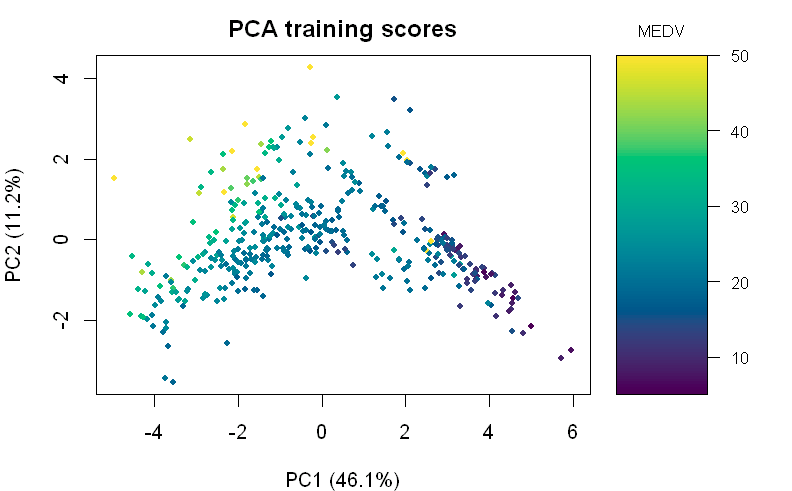

In [9]:
palette <- hcl.colors(128, "Viridis")
target_range <- range(y_train)
breaks <- seq(target_range[1], target_range[2], length.out = length(palette) + 1)
point_colours <- palette[findInterval(y_train, breaks, rightmost.closed = TRUE)]

plot_embeddings <- function(panels, titles, rows, cols, width, height,
                            xlabel, ylabel) {
  options(repr.plot.width = width, repr.plot.height = height)
  slots <- matrix(seq_len(rows * cols), nrow = rows, byrow = TRUE)
  layout(cbind(slots, rep(rows * cols + 1L, rows)), widths = c(rep(1, cols), 0.30))
  par(mar = c(4, 4, 2.3, 0.8))
  for (i in seq_along(panels)) {
    plot(panels[[i]][, 1], panels[[i]][, 2], xlab = xlabel, ylab = ylabel,
         main = titles[i], col = point_colours, pch = 19, cex = 0.64)
  }
  par(mar = c(4, 0.3, 2.3, 3.5))
  midpoints <- head(breaks, -1L) + diff(breaks) / 2
  image(0.5, midpoints, matrix(midpoints, nrow = 1), col = palette,
        xlim = c(0, 1), ylim = target_range, axes = FALSE, xlab = "", ylab = "")
  ticks <- pretty(target_range, n = 5)
  axis(4, at = ticks[ticks >= target_range[1] & ticks <= target_range[2]],
       las = 1, cex.axis = 0.85)
  mtext("MEDV", side = 3, line = 0.6, cex = 0.8)
  box()
  layout(1)
  par(mar = c(5.1, 4.1, 4.1, 2.1))
}
plot_embeddings(
  list(train_scores), "PCA training scores", 1, 1, 6.6, 4.1,
  sprintf("PC1 (%.1f%%)", 100 * variance[1]),
  sprintf("PC2 (%.1f%%)", 100 * variance[2])
)

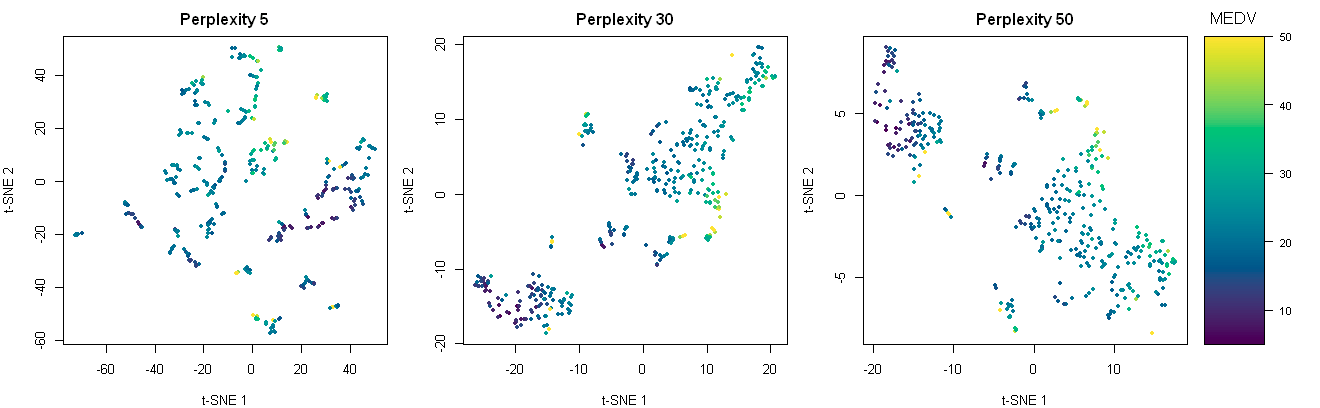

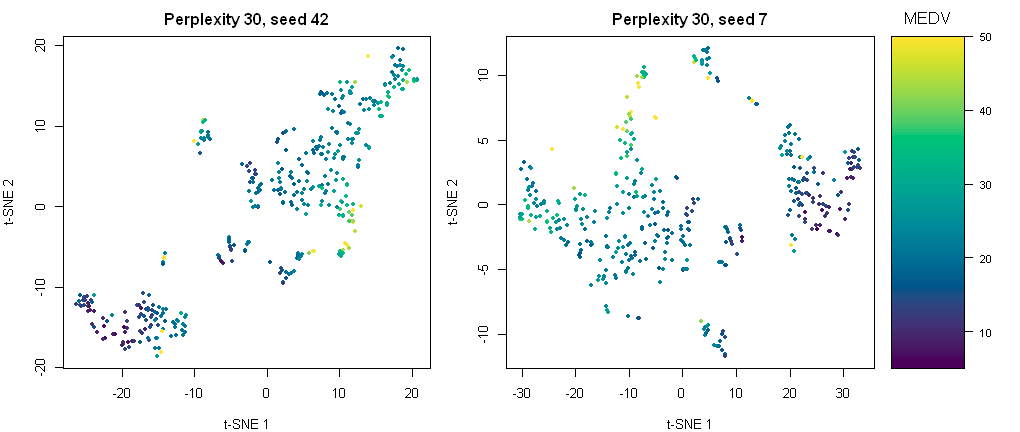

In [10]:
perplexities <- c(5L, 30L, 50L)
stopifnot(all(perplexities < nrow(train_scaled)),
          all(3L * perplexities < nrow(train_scaled) - 1L))

embed_tsne <- function(perplexity, random_seed) {
  set.seed(random_seed)
  Rtsne::Rtsne(
    train_scaled, dims = 2L, perplexity = perplexity,
    pca = FALSE, normalize = FALSE, check_duplicates = FALSE,
    eta = 200, theta = 0.5, max_iter = 1000L, exaggeration_factor = 12,
    stop_lying_iter = 250L, mom_switch_iter = 250L, num_threads = 1L
  )$Y
}
tsne <- setNames(lapply(perplexities, embed_tsne, random_seed = seed),
                 perplexities)
plot_embeddings(tsne, paste("Perplexity", perplexities),
                1, 3, 11, 3.4, "t-SNE 1", "t-SNE 2")
tsne_seed7 <- embed_tsne(30L, 7L)
plot_embeddings(list(tsne[["30"]], tsne_seed7),
                c("Perplexity 30, seed 42", "Perplexity 30, seed 7"),
                1, 2, 8.5, 3.6, "t-SNE 1", "t-SNE 2")

## 9. Visualise UMAP

Use Euclidean distance, two components, seed 42, spectral initialisation, one worker for neighbours and optimisation, 500 epochs, and spread 1. Compare 5, 15 and 50 neighbours at minimum distance 0.1. Isolate the minimum-distance effect at 15 neighbours by using the same 0.1 result for comparison with 0.5. UMAP and t-SNE are used for visual exploration.

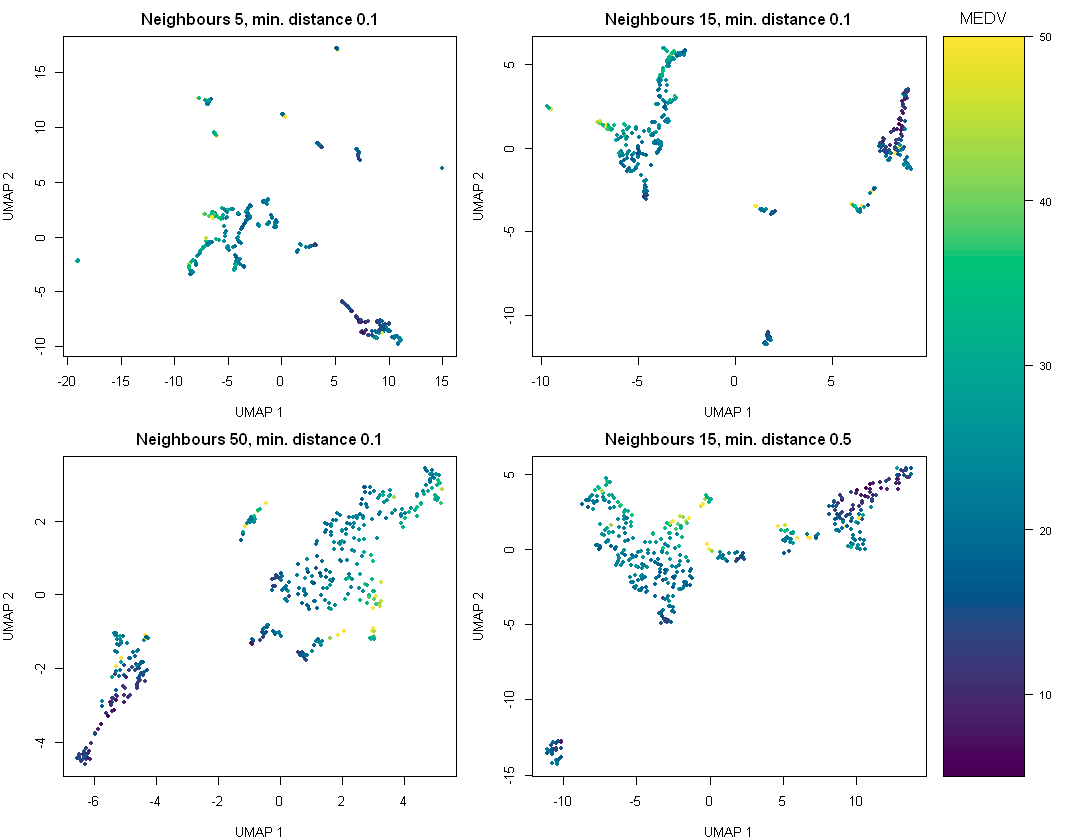

In [11]:
settings <- data.frame(neighbours = c(5L, 15L, 50L, 15L),
                       min_dist = c(0.1, 0.1, 0.1, 0.5))
umap <- lapply(seq_len(nrow(settings)), function(i) {
  set.seed(seed)
  uwot::umap(
    train_scaled, n_components = 2L, n_neighbors = settings$neighbours[i],
    min_dist = settings$min_dist[i], metric = "euclidean",
    init = "spectral", spread = 1, n_epochs = 500L,
    n_threads = 1L, n_sgd_threads = 1L, verbose = FALSE
  )
})
plot_embeddings(
  umap, sprintf("Neighbours %d, min. distance %.1f",
                settings$neighbours, settings$min_dist),
  2, 2, 9, 7.0, "UMAP 1", "UMAP 2"
)

In [12]:
# Compare local target differences and seed stability by observation identity.
neighbours_of <- function(points) {
  distance <- as.matrix(dist(points))
  diag(distance) <- Inf
  t(apply(distance, 1, order)[seq_len(10), , drop = FALSE])
}
embeddings <- c(
  list("Standardised predictors" = train_scaled, "PCA (two axes)" = train_scores[, 1:2]),
  setNames(tsne, sprintf("t-SNE p=%d, seed 42", perplexities)),
  list("t-SNE p=30, seed 7" = tsne_seed7),
  setNames(umap, sprintf("UMAP n=%d, d=%.1f", settings$neighbours, settings$min_dist))
)
near <- lapply(embeddings, neighbours_of)
gaps <- vapply(near, function(index) {
  neighbour_targets <- matrix(y_train[index], nrow(index), ncol(index))
  mean(abs(y_train - neighbour_targets))
}, numeric(1))
original <- near[["Standardised predictors"]]
anchor <- which.min(apply(original, 1, function(index) median(y_train[index])))
original_neighbours <- original[anchor, ]
kept <- vapply(near, function(index) {
  length(intersect(original_neighbours, index[anchor, ]))
}, integer(1))
print(data.frame(Representation = names(gaps), Mean_MEDV_gap = round(gaps, 3),
                 Anchor_neighbours_retained = kept), row.names = FALSE)
profile_rows <- c(anchor, original_neighbours)
profile_features <- c("RM", "LSTAT")
cat("Low-MEDV anchor is data row", train_index[anchor], "(header excluded).\n")
print(round(rbind(
  "Anchor and 10 original neighbours" =
    vapply(train_imputed[profile_rows, profile_features], median, numeric(1)),
  "Training set" = vapply(train_imputed[profile_features], median, numeric(1))
), 2))
cat("Neighbourhood median MEDV:", median(y_train[profile_rows]), "\n")
a <- near[["t-SNE p=30, seed 42"]]
b <- near[["t-SNE p=30, seed 7"]]
seed_overlap <- mean(vapply(seq_len(nrow(a)), function(i) {
  length(intersect(a[i, ], b[i, ])) / 10
}, numeric(1)))
cat(sprintf("Mean 10-neighbour overlap across t-SNE seeds: %.1f%%\n",
            100 * seed_overlap))

          Representation Mean_MEDV_gap Anchor_neighbours_retained
 Standardised predictors         4.366                         10
          PCA (two axes)         5.113                          3
      t-SNE p=5, seed 42         5.094                          6
     t-SNE p=30, seed 42         4.708                          6
     t-SNE p=50, seed 42         4.703                          7
      t-SNE p=30, seed 7         4.595                          6
         UMAP n=5, d=0.1         5.244                          7
        UMAP n=15, d=0.1         5.098                          7
        UMAP n=50, d=0.1         4.878                          7
        UMAP n=15, d=0.5         4.920                          7


Low-MEDV anchor is data row 406 (header excluded).


                                    RM LSTAT
Anchor and 10 original neighbours 5.53 23.69
Training set                      6.19 11.43


Neighbourhood median MEDV: 8.5 


Mean 10-neighbour overlap across t-SNE seeds: 83.9%


## 10. Interpret results in Python and R

### Test performance and compression

The 13-input baseline led on all three test metrics with RMSE **2.849**, MAE **2.184**, and R² **0.921**. Lasso and Elastic Net increased RMSE by 0.103 and 0.094 MEDV units, respectively. Their observed-versus-predicted plots follow the baseline closely. Elastic Net had the lowest RMSE among the reduced pipelines on this split.

PCA retained **8 components** (38.5% fewer inputs) and explained **92.84%** of training predictor variance. Its RMSE rose to **4.201**. The PCA forest missed several high observed values by a wide margin. PCA preserves predictor variance and changes the directions available for the forest's splits, so even a high retained variance can give weaker predictions.

Lasso retained **8 predictors** (38.5% fewer) and Elastic Net retained **9 predictors** (30.8% fewer). Forest fitting took 0.310 s for the baseline and PCA 0.320 s, Lasso 0.210 s, Elastic Net 0.240 s. The two feature subsets fit faster, while PCA took about as long as the baseline. These are single-run timings and the accuracy differences come from one holdout split.

### Selected predictors

Lasso at lambda 0.35 retained eight predictors. Elastic Net at lambda 0.55 and L1 ratio 0.5 retained those eight plus INDUS. INDUS correlated with NX (r = 0.76) and DIS (r = -0.71). The L2 term allows correlated predictors to share weight, and the two fits also used different penalty strengths. The selectors produce column subsets, and the Random Forest generates the final predictions.

### Visual structure and sensitivity

Colours generally darken towards positive PC1, especially in the right-hand arm. Moderate and high MEDV values overlap more in the broader cloud. The two-axis PCA has an average absolute MEDV difference of 5.113 between neighbouring points, compared with 4.366 in the 13 standardised inputs.

For example, data row 406 and its ten nearest neighbours in the original standardised space had median MEDV 8.5. Their median RM was 5.53 and median LSTAT was 23.69, versus 6.19 and 11.43 in the training set. The anchor counts in Section 9 show how many of its original neighbours each embedding preserved.

The low-MEDV group remains visible across PCA, t-SNE and UMAP, although high values are interspersed with moderate ones. At perplexity 5, t-SNE breaks the sample into small islands. At 30 and 50, broader groups emerge. Changing the seed at 30 moves or rotates the groups, while the mean overlap of each point's ten nearest neighbours is **83.9%**.

UMAP shows smaller, more separated patches with 5 neighbours and broader groups with 50. At 15 neighbours, raising the minimum distance from 0.1 to 0.5 spreads out the denser patches while retaining the low-value region. Relative positions, group areas and gaps change with the settings. These plots describe the training predictors and do not establish predictive accuracy.

### Python and R comparison

| Pipeline | Python inputs | Python RMSE | R inputs | R RMSE |
|---|---:|---:|---:|---:|
| Baseline | 13 | 3.005 | 13 | 2.849 |
| PCA + RF | 7 | 4.255 | 8 | 4.201 |
| Lasso + RF | 8 | 3.077 | 8 | 2.952 |
| Elastic Net + RF | 10 | 3.029 | 9 | 2.944 |

Both runs rank the baseline first on RMSE, MAE and R². Elastic Net has the smallest RMSE increase among the reduced models, and PCA incurs the largest increase. The Lasso subsets match across languages. Both Elastic Net subsets add INDUS, and Python also retains TAX. PCA needs seven components in Python and eight in R to meet the same 90% rule. Both sets of embeddings show low-value neighbourhoods despite differences in layout. Each language generated its own training/test split using seed 42. The splits, random-number generators and implementations can all contribute to the numerical differences.

### Software versions

In [13]:
cat(R.version.string, "\n")
for (package in c("ranger", "glmnet", "Rtsne", "uwot", "IRkernel", "repr")) {
  cat(package, ": ", as.character(packageVersion(package)), "\n", sep = "")
}

R version 4.6.1 (2026-06-24 ucrt) 


ranger: 0.18.0
glmnet: 5.2
Rtsne: 0.17
uwot: 0.2.5
IRkernel: 1.3.2
repr: 1.1.7
